In [1]:
!wget -q https://archive.ics.uci.edu/static/public/320/student+performance.zip -O student.zip
!unzip -o student.zip
!mkdir -p student_data
!unzip -o student.zip -d student_data

Archive:  student.zip
 extracting: .student.zip_old        
 extracting: student.zip             
Archive:  student.zip
  inflating: student_data/student-mat.csv  
  inflating: student_data/student-por.csv  
  inflating: student_data/student-merge.R  
  inflating: student_data/student.txt  


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("student_data/student-por.csv", sep=";")

print(df.shape)

(649, 33)


In [3]:
missing = df.isnull().sum()

print(missing[missing > 0])

if missing.sum() == 0:
    print("No missing values found in the dataset.")

Series([], dtype: int64)
No missing values found in the dataset.


### Missing Value Decisions

All 33 columns contain zero missing values.
Therefore, no rows or columns need to be removed,
and no imputation is necessary.
The original dataset is retained without changes.

In [4]:
Q1 = df["absences"].quantile(0.25)
Q3 = df["absences"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["absences"] < lower) |
    (df["absences"] > upper)
]

print("Lower limit:", lower)
print("Upper limit:", upper)
print("Number of outliers:", len(outliers))

print(outliers[["age", "absences", "G3"]].head(10))

Lower limit: -9.0
Upper limit: 15.0
Number of outliers: 21
     age  absences  G3
40    16        16  10
103   15        16  10
150   15        24   9
155   17        22   6
161   16        16   8
197   17        32  14
206   17        16  12
211   16        16  12
212   17        30  16
217   17        21  13


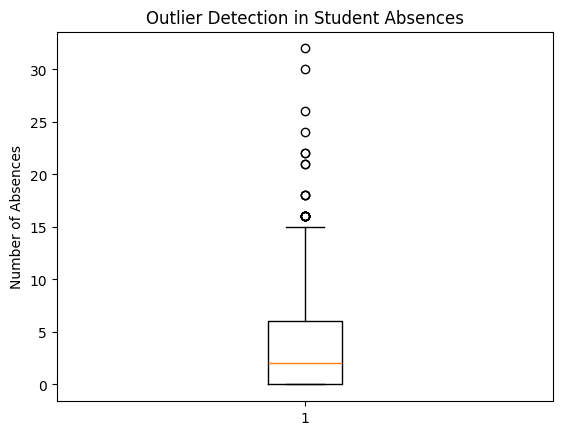

In [5]:
plt.boxplot(df["absences"])
plt.title("Outlier Detection in Student Absences")
plt.ylabel("Number of Absences")
plt.show()

### Outlier Analysis

The IQR method was used to identify extreme values
in the absences column.

High absence values are not automatically data-entry
errors. They may represent genuine student absences.

Therefore, the identified values are retained unless
there is evidence that they are incorrect.

In [6]:
print(df.dtypes)

school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object


### Data Type Correction

The numerical columns are stored as integer values,
and categorical columns are stored as object values.

No obvious incorrect data types were identified.
Therefore, no type conversion was necessary.

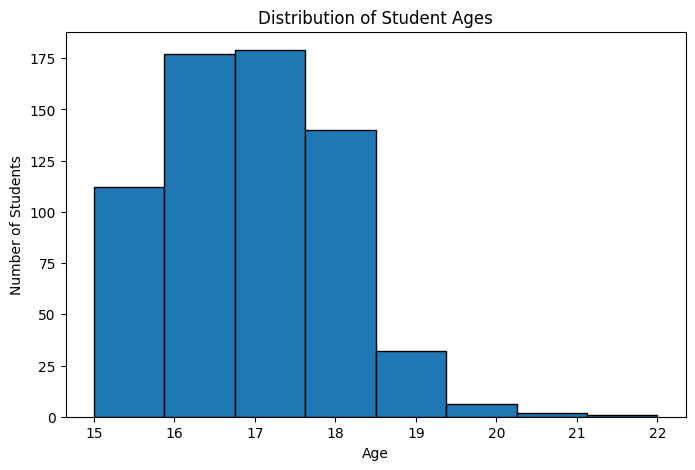

In [7]:
plt.figure(figsize=(8, 5))

plt.hist(df["age"], bins=8, edgecolor="black")

plt.title("Distribution of Student Ages")
plt.xlabel("Age")
plt.ylabel("Number of Students")

plt.show()

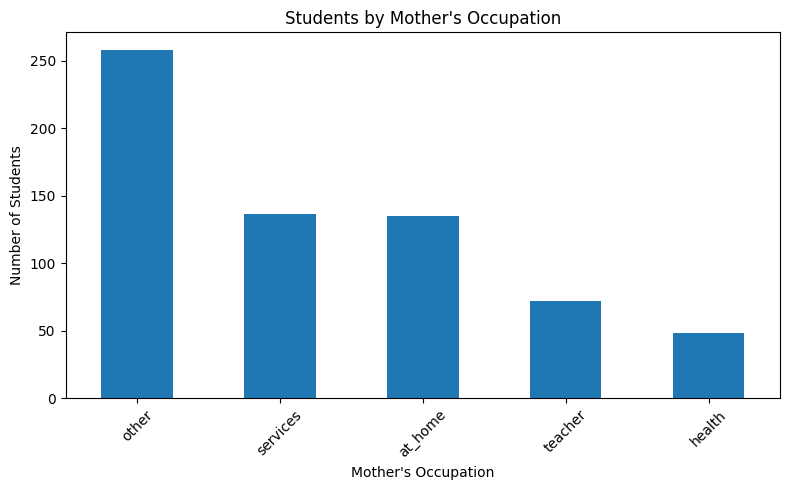

In [8]:
plt.figure(figsize=(8, 5))

df["Mjob"].value_counts().plot(kind="bar")

plt.title("Students by Mother's Occupation")
plt.xlabel("Mother's Occupation")
plt.ylabel("Number of Students")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

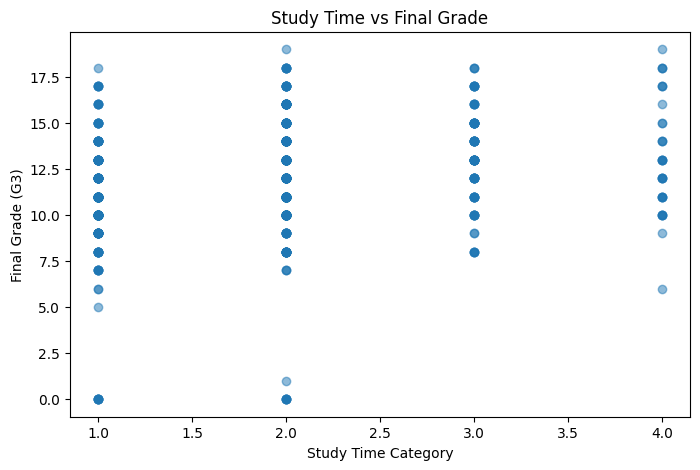

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(df["studytime"], df["G3"], alpha=0.5)

plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time Category")
plt.ylabel("Final Grade (G3)")

plt.show()

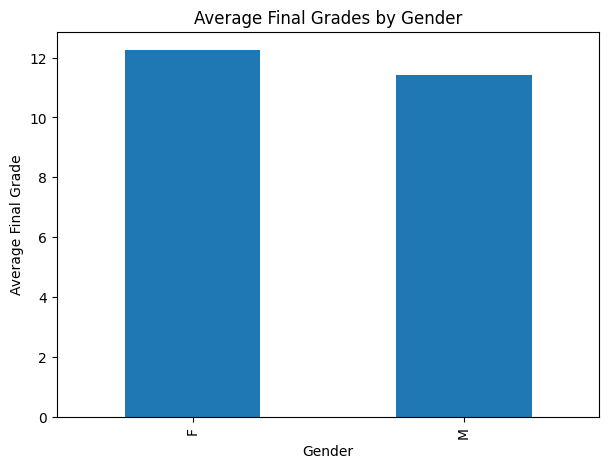

In [10]:
plt.figure(figsize=(7, 5))

average_grades = df.groupby("sex")["G3"].mean()

average_grades.plot(kind="bar")

plt.title("Average Final Grades by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Final Grade")

plt.show()

<Figure size 900x500 with 0 Axes>

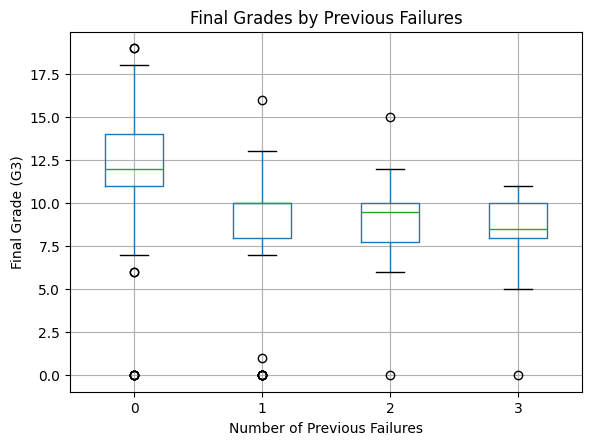

In [11]:
plt.figure(figsize=(9, 5))

df.boxplot(column="G3", by="failures")

plt.title("Final Grades by Previous Failures")
plt.suptitle("")
plt.xlabel("Number of Previous Failures")
plt.ylabel("Final Grade (G3)")

plt.show()

## Five Findings from the Dataset

1. The dataset contains 649 students from two Portuguese schools.

2. The average student age is approximately 16.74 years.

3. The average final grade is approximately 11.91 out of 20.

4. The absences column has a maximum value of 32, while its median is only 2.

5. Students with higher study-time categories and fewer previous failures
   are worth investigating when studying academic performance.

In [12]:
print("Dataset:", df.shape)

print("Missing Values:", df.isnull().sum().sum())

print("Outliers in Absences:", len(outliers))

print("Charts completed: 5")

Dataset: (649, 33)
Missing Values: 0
Outliers in Absences: 21
Charts completed: 5
